# Architecture in the cloud, monitoring and maintenance

After this block you can sketch the architecture of a data application (front end, back end, database) and name the cloud services that run each part, and you can keep a deployed model useful: measure data drift with the KS test and the population stability index, detect label shift once labels arrive, decide on retraining with a written rule, and document the model in a model card. This serves the second and third learning outcomes of Session 16.

The case study provides real examples. France sends a larger share of the requests in 2026 than in earlier years; the mix of goods changes from year to year; and the decisions of 2026 in your own data can play the requests that reach a service released at the start of 2026, first without and later with their headings. The block ends with version 2 of the model, retrained with the labels of 2026, and the score a team reports for it.

## Overview

| Section | What it covers |
|---|---|
| Setup · version 1 of the model and the requests of 2026 | the validation design, a simulated release date, the decisions of 2026 as production requests, version 1 with a random and a time-based validation score |
| System design: front end, back end and database | the three parts and why they are separated, three common designs, Docker Compose, a prediction log in SQLite, publishing a dashboard with Streamlit |
| Cloud services for the application on AWS | ECR, ECS on Fargate, the load balancer, RDS, S3, Secrets Manager, CloudWatch, costs |
| Monitoring: data drift with the KS test and the population stability index | data drift, the KS test, p-values in large samples, the PSI and its binning, country and language drift, the reference period, Wasserstein and Jensen-Shannon distances, drift reports, text drift with a domain classifier, words the model has never seen |
| Monitoring: prediction drift and label shift | data drift, label shift and concept drift, the nomenclature revision, prediction drift, the labels of 2026, unseen headings, accuracy on 2026 |
| Retraining triggers and versioning | a written retraining rule, candidates compared on the newest labelled data, the standard error of an accuracy, versioning and rollback |
| Documenting a model in a model card | the sections of a model card, results per language, a card generated with skops |
| Worked example | version 2, the score a team reports, and the independent evaluation |
| Check your understanding, Exercises, Debrief | five questions, seven exercises in pairs, what to compare afterwards |

The monitoring loop that the block builds, from the running service to a new version:

```mermaid
flowchart LR
    S["Service v1<br/>in production"] --> L["Prediction log<br/>(database)"]
    L --> I["Without labels:<br/>input drift,<br/>prediction drift"]
    F["Labels arrive later<br/>(headings of 2026)"] --> P["With labels:<br/>label shift, accuracy"]
    I --> R{"Retraining rule"}
    P --> R
    R -->|no| S
    R -->|yes| T["Retrain candidates,<br/>compare on newest data"]
    T --> V["Release v2,<br/>update model card"]
    V --> S
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## Setup · version 1 of the model and the requests of 2026

`decisions.parquet` mixes all years, and how to split it is each team's design decision ([final project](../../17-18-final-presentations/final-project.md)). This notebook uses the design of Block 1: 14,635 **validation decisions** (`val`), one fold of seven drawn at random and stratified by heading and language together, are never used for training; the rest is the training part (`train`). To watch a model age, the notebook then simulates a release date: version 1 is trained only on the training decisions that started **before 1 January 2026** (late 2023 to 2025).

The training decisions that started in 2026 (`production`) play the requests that v1 receives after its release: first we look only at their inputs (`new`), as a running service does, and we use their headings once the labels "arrive". v1 never sees them in training. The validation decisions, which no model of this notebook is trained on (`holdout`), give the honest scores.

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

DATA = Path("case-study/data/ebti")
decisions = pd.read_parquet(DATA / "decisions.parquet")
key = decisions["heading"] + "|" + decisions["language"]       # stratify by heading and language together
folds = StratifiedKFold(n_splits=7, shuffle=True, random_state=0)  # one fold of seven for validation
train_rows, valid_rows = next(folds.split(decisions, key))         # warns: some combinations are tiny
train, val = decisions.iloc[train_rows], decisions.iloc[valid_rows]
RELEASE = pd.Timestamp("2026-01-01")                    # v1 is trained on decisions before this date
old = train[train["start_date"] < RELEASE]              # v1's training data

production = train[train["start_date"] >= RELEASE].copy()   # the requests after the release, labels arrive later
holdout = val.copy()                                    # never used for training: the honest scores
inputs = ["bti_reference", "issuing_country", "language", "start_date", "description"]
new = production[inputs].copy()                         # what the running service sees: inputs only, no heading
print(f"{len(old):,} training decisions before 2026 | {len(new):,} requests of 2026 | {len(holdout):,} hold-out decisions")

/Users/danielle/Documents/code/python_ml_ai/.venv/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=7.
  warnings.warn(


64,059 training decisions before 2026 | 23,746 requests of 2026 | 14,635 hold-out decisions


Next we train version 1 of the model, as in Block 1 but on all training decisions before 2026: word TF-IDF and a linear SVM. This is the model "in production" during 2026. `n_jobs=-1` trains the one-against-the-rest classifiers of the headings on all processor cores. Two scores estimate how well it will do: the accuracy on the hold-out decisions of the same years (a **random** hold-out, like the validation design above), and the accuracy of the same model type trained on the oldest 80 % and tested on the newest 20 % (a **time-based** hold-out, as in Block 1). About one to two minutes, depending on the machine.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline

def make_model():
    return make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2),
                         SGDClassifier(loss="hinge", alpha=1e-5, max_iter=20, tol=None, random_state=0,
                                       n_jobs=-1))                         # all processor cores

v1 = make_model().fit(old["description"], old["heading"])
new["pred_v1"] = v1.predict(new["description"])
production["pred_v1"] = v1.predict(production["description"])
holdout["pred_v1"] = v1.predict(holdout["description"])
same_years = holdout[holdout["start_date"] < RELEASE]
acc_random = accuracy_score(same_years["heading"], v1.predict(same_years["description"]))
ordered = old.sort_values("start_date", kind="stable")
cut = int(len(ordered) * 0.8)                                            # newest 20 % held out
early = make_model().fit(ordered["description"][:cut], ordered["heading"][:cut])
acc_time = accuracy_score(ordered["heading"][cut:], early.predict(ordered["description"][cut:]))
print(len(v1.classes_), "headings known to v1")
print(f"validation accuracy: random hold-out {acc_random:.3f} | time-based hold-out {acc_time:.3f} "
      f"(newest 20 % from {ordered['start_date'].iloc[cut].date()})")

960 headings known to v1
validation accuracy: random hold-out 0.880 | time-based hold-out 0.795 (newest 20 % from 2025-07-21)


## System design: front end, back end and database

This section and the next are an introduction. The aim is that you can read and sketch the architecture of a data application and know which cloud services exist for each part, not that you operate them.

**System design** is the decision about which parts an application consists of, what each part does and how the parts communicate. Most data applications follow the same three-part pattern:

| Part | What it does | In the tariff example |
|---|---|---|
| **Front end** | what users see and click: a web page or a dashboard | a Streamlit dashboard where an officer pastes a description |
| **Back end** | the logic behind it, offered as an API: validation, the model, the rules | the FastAPI service of Block 1 that returns the top three headings |
| **Database** | data that must outlive a single request | a SQLite file with the prediction log, the raw material of monitoring |

```mermaid
flowchart LR
    U["User<br/>(browser)"] -->|HTTPS| FE["Front end<br/>Streamlit dashboard"]
    FE -->|"HTTP + JSON<br/>POST /predict"| BE["Back end<br/>FastAPI + model"]
    P["Other programs"] -->|"HTTP + JSON"| BE
    BE -->|SQL| DB[("Database<br/>SQLite file")]
```

The parts talk over the network: the front end sends HTTP requests with JSON to the back end (Block 1), the back end sends SQL to the database (Session 3). Only the front end and the API are reachable from outside; the database is not. Why separate the parts instead of writing one script?

- **One model, several clients.** The dashboard, a batch job and another team's software all use the same API, and a new model version is deployed in one place.
- **Independent scaling.** If many requests arrive, more copies of the back end are started; the database stays one.
- **Security.** The database holds the data and is reachable only from the back end, never from the internet.
- **Replaceable parts.** The Streamlit front end can later become a web page without touching the model.

Not every project needs all three parts. Three common designs:

| Design | Parts | Example |
|---|---|---|
| Interactive model service | front end → back end → database | the tariff heading service of the workspace |
| Analytics dashboard | front end → database, refreshed by a scheduled job | a dashboard of Berlin rental prices, reloaded every night |
| Batch scoring | scheduled job → database → reporting tool | churn scores computed every Monday for all customers and read by the CRM team |

### Locally: Docker Compose

**Locally**, front end and back end each run in their own container, and **Docker Compose** starts them together from one file, `compose.yaml`. The containers share a private network in which they find each other by service name: the dashboard calls `http://api:8000`. The database is a SQLite file on a **volume**, a storage area that Docker keeps when a container is replaced. Only the API container mounts it, so the log survives a restart and cannot be reached from outside. `workspace/compose.yaml`, shortened:

```yaml
services:
  api:                                    # back end: the image of the Dockerfile (Block 1)
    build: .
    environment: {PREDICTION_DB: /app/data/predictions.sqlite}
    volumes: ["prediction-data:/app/data"]   # database: a SQLite file that only the API sees
    ports: ["8000:8000"]
  dashboard:                              # front end: sends every description to the API
    build: dashboard
    environment: {API_URL: "http://api:8000"}
    depends_on: {api: {condition: service_healthy}}
    ports: ["8501:8501"]
volumes:
  prediction-data:
```

```bash
cd sessions/16-deployment-and-monitoring/workspace
docker compose up --build        # dashboard: http://localhost:8501, API: http://localhost:8000/docs
docker compose logs api          # what the API printed
docker compose down              # add -v to delete the volume with the log as well
```

The service code hardly changes: with the environment variable `PREDICTION_DB` set, the API writes its prediction log to a SQLite table, and with `API_URL` set, the dashboard calls the API instead of loading the model. Settings that differ between laptop and cloud come from the environment, not from the code.

### The database part: a prediction log

Monitoring needs a record of what the service did. The workspace's `SQLitePredictionLogger` writes one row per request: time, model version, description length, language, top heading and its score. It deliberately does **not** store the description, which is confidential business information before a decision.

Next we play one quarter of service: v1 answers the requests of January to March 2026, and we log them into a SQLite database. `sqlite3.connect(":memory:")` creates a database that lives only in memory (nothing is written to disk), and `executemany` inserts many rows in one call. `decision_function` gives the margin of every heading; `.max(axis=1)` keeps the top score.

In [4]:
import sqlite3

db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE predictions (time TEXT, model_version TEXT, text_length INTEGER, "
           "language TEXT, heading TEXT, top_score REAL)")
q1 = new[new["start_date"] < "2026-04-01"]
top_score = v1.decision_function(q1["description"]).max(axis=1)
rows = zip(q1["start_date"].astype(str), ["1.0.0"] * len(q1), q1["description"].str.len().tolist(),
           q1["language"], q1["pred_v1"], top_score.round(3).tolist())
db.executemany("INSERT INTO predictions VALUES (?, ?, ?, ?, ?, ?)", rows)
print(db.execute("SELECT COUNT(*) FROM predictions").fetchone()[0], "logged predictions")

7313 logged predictions


**Predict before running.** For which language do you expect the lowest average top score, the one most heavily represented in training or a rare one? The SQL query groups the log by language (Session 3).

In [5]:
query = '''SELECT language, COUNT(*) AS n, ROUND(AVG(top_score), 3) AS mean_score,
                  ROUND(AVG(top_score < 0), 3) AS share_unsure
           FROM predictions GROUP BY language HAVING n >= 40 ORDER BY n DESC'''
pd.read_sql(query, db)

,language,n,mean_score,share_unsure
0,de,4604,1.008,0.098
1,fr,907,-0.008,0.583
2,nl,381,-0.268,0.748
3,cs,367,-0.209,0.717
4,es,254,-0.142,0.689
5,pl,206,-0.279,0.743
6,it,148,-0.404,0.797
7,ro,82,-0.396,0.817
8,sv,64,-0.277,0.766
9,da,60,-0.475,0.783


**Reading the result.** The log alone, without any label, already shows where the model is unsure: a negative top score means the model does not really vote for any heading. This is the first monitoring signal, and it is available on day one. The rest of this notebook computes the others from the same kind of data.

One SQLite file serves one API container well. When several copies of the back end on different machines must write to the same data, the SQLite documentation recommends a client/server database instead, and that is what the cloud offers as a managed service.

### Publishing a dashboard

Not every model needs an API. For many projects, the users are people who want to explore results: a **dashboard** is a web page with charts, filters and perhaps a form that calls the model. **Streamlit** turns a Python script into such a web app: every widget (`st.text_area`, `st.selectbox`) is a line of Python, and the script reruns when the user changes an input. `@st.cache_resource` keeps the loaded model in memory between reruns. The core of `workspace/dashboard/streamlit_app.py` (shown, not run):

```python
# requires: uv sync --extra dashboard, then: MODEL_DIR=models uv run streamlit run dashboard/streamlit_app.py
import os
from pathlib import Path

import pandas as pd
import streamlit as st

from tariff_service.model import decision_text, load_model, top_k

@st.cache_resource                      # load once per server process
def get_model():
    return load_model(Path(os.environ.get("MODEL_DIR", "models")))

pipe, meta = get_model()
st.title("Tariff heading suggestion")
st.caption(f"Model {meta['model_version']} · validation accuracy {meta['validation']['accuracy']}")
text = st.text_area("Description of goods", "Masque de protection à usage unique, en non-tissé")
ranked = top_k(pipe, [decision_text(text)], k=3)[0]          # [(heading, score), ...]
st.dataframe(pd.DataFrame([{"heading": h, "score": sc, "text": meta["headings"].get(h, "")}
                           for h, sc in ranked]))
```

Publishing options differ in what they run and what they cost; free tiers change often, so check the current terms before you choose.

| Option | Runs | Fits | Notes |
|---|---|---|---|
| Streamlit Community Cloud | Streamlit apps from a public GitHub repository | team dashboards, course projects | free; the app sleeps when unused |
| Hugging Face Spaces | Gradio, Streamlit, static and Docker apps | model demos | free hardware only for some app types |
| Render, Google Cloud Run and similar | any container image | the API container | free quotas with limits; some need a billing account |
| A university or company server | containers with Docker or Podman | internal or personal data | data stay inside the organisation |
| A static report (Quarto, Jupyter Book on GitHub Pages) | HTML without a server | results that need no live predictions | cheapest and most robust |

```mermaid
flowchart TD
    Q{"Do users need live<br/>predictions?"} -->|no| ST["Static report:<br/>GitHub Pages"]
    Q -->|yes| P{"Are the users<br/>people or programs?"}
    P -->|programs| API["API container:<br/>Cloud Run, Render, server"]
    P -->|people| D{"Personal or<br/>confidential data?"}
    D -->|yes| IN["Internal server<br/>or company cloud"]
    D -->|no| SC["Streamlit Community Cloud<br/>or Hugging Face Spaces"]
```

A public free tier is fine for a demo on published BTI decisions, not for pending requests, which contain confidential business information. A public dashboard is public: anyone can use it, and every prediction costs computing time.

## Cloud services for the application on AWS

**In the cloud**, the same three parts run on managed services: the provider runs the machines, installs updates and makes backups, and you pay for what you use. Amazon Web Services (AWS) offers a service for each part.

**Predict.** Locally, the prediction log is one SQLite file on a volume. Once three copies of the API run on different machines, where should the log live, and why? Check your guess against the table.


| Part | Locally (Compose) | AWS service | What the service does |
|---|---|---|---|
| Container images | `docker build` | **Amazon ECR** (Elastic Container Registry) | stores the images that CI builds |
| Front end and back end | containers `dashboard`, `api` | **Amazon ECS with AWS Fargate** | runs containers without managing servers; starts more copies under load |
| Entry point | `ports:` | **Elastic Load Balancing** (Application Load Balancer) | receives HTTPS traffic and spreads it over the containers |
| Database | SQLite file on a volume | **Amazon RDS** (Relational Database Service) | a managed SQL database server (for example PostgreSQL) with backups and updates |
| Files: model, raw data | `models/` folder | **Amazon S3** | object storage for files of any size |
| Passwords and keys | `environment:` | **AWS Secrets Manager** | stores secrets and passes them to the containers |
| Logs, metrics, alarms | `docker compose logs` | **Amazon CloudWatch** | collects logs and metrics and raises alarms |

```mermaid
flowchart LR
    GH["GitHub Actions<br/>(cd.yml)"] -->|push image| ECR["Amazon ECR"]
    U["Users"] -->|HTTPS| LB["Load balancer"]
    subgraph ECS["Amazon ECS on Fargate"]
        FE["dashboard<br/>container"]
        BE["api<br/>containers"]
    end
    ECR -.->|pull| ECS
    LB --> FE
    LB --> BE
    FE --> BE
    BE --> RDS[("Amazon RDS<br/>SQL database")]
    BE -.->|model files| S3["Amazon S3"]
    ECS -.->|logs, metrics| CW["Amazon CloudWatch"]
```

Read the diagram as the story of one release: CD pushes the image to ECR (Block 1); ECS pulls it and runs the containers; the load balancer sends users to them; the API writes its prediction log to RDS and reads the model from S3; CloudWatch collects the logs and raises an alarm when, for example, the share of unsure answers rises. Microsoft Azure and Google Cloud offer the same building blocks under other names, for example Azure Container Apps or Google Cloud Run for the containers and Azure SQL Database or Google Cloud SQL for the database. The design stays the same; only the names change.

Data scientists rarely set up cloud infrastructure alone, but they take part in the decisions: where the model runs, where the data live, who can reach them and what it costs. An architecture sketch is the common language for these discussions with engineers, IT security and the budget holder. It also makes data protection visible: in the diagram you can point to the one place where confidential requests could be stored (here: nowhere, because the log keeps no descriptions).

In practice, AWS, Azure and Google Cloud each publish a *well-architected framework* with design principles for reliability, security, cost and performance, and companies with many services often move from ECS to Kubernetes (Amazon EKS, Azure AKS, Google GKE).

> **Note.** Cloud resources cost money while they exist, whether or not anyone uses them: a load balancer and a database are billed by the hour. Free offers for new accounts are limited in time and amount, and their terms change; check them, set a budget alarm, and delete what you created after an experiment.

## Monitoring: data drift with the KS test and the population stability index

A deployed model starts to age on its first day. The requests change, the goods change, the member states that send requests change, and the nomenclature itself is revised every five to six years (HS 2017, HS 2022, and HS 2028, effective 1 January 2028 according to the World Customs Organization, checked October 2026). **Monitoring** compares what the service sees now with what it was trained on.

**Data drift** (also *covariate shift*) is a change in the distribution of the inputs between the **reference** data (training or validation data) and the **current** data (recent requests). Labels arrive late (in the case study, when the lecturer releases them) or never, but inputs are available at once, so input drift is the earliest warning that the model is used on data unlike its training data. For text we monitor summaries of the input: the length of the description, the language, the issuing country, the share of words the model has never seen.

### The Kolmogorov–Smirnov test

For one numeric feature, the two-sample **KS test** compares the two **empirical distribution functions** (ECDF): for every value t, the share of observations at or below t. Its statistic D is the largest vertical distance between the two curves, from 0 (identical) to 1 (no overlap). A worked example: reference [1, 2, 3, 4], current [3, 4, 5, 6]. At t = 2, 50 % of the reference and 0 % of the current values are at or below t; no point has a larger gap, so D = 0.5. `scipy.stats.ks_2samp` computes D and a p-value; next we check the hand calculation.

In [6]:
from scipy import stats

stats.ks_2samp([1, 2, 3, 4], [3, 4, 5, 6]).statistic

np.float64(0.5)

Next we compare the length of the descriptions (on a log scale, because a few are very long) in v1's training data and in the requests of 2026. `np.log1p(x)` computes log(1 + x).

**Predict before running.** Do the 2026 descriptions look very different in length? Guess D: about 0.01, 0.1 or 0.5?

In [7]:
ref_len = np.log1p(old["description"].str.len())
cur_len = np.log1p(new["description"].str.len())
ks = stats.ks_2samp(ref_len, cur_len)
print(f"D = {ks.statistic:.3f}, p = {ks.pvalue:.2f}")

D = 0.012, p = 0.01


Next we draw the two ECDFs and mark where the gap D is largest, to see what the statistic measures. `np.searchsorted(sorted_values, grid, side="right") / n` evaluates an ECDF at many points at once.

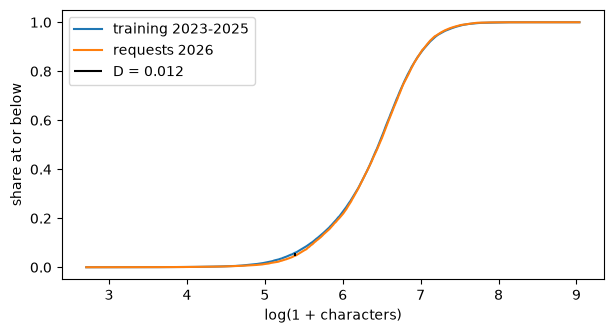

In [8]:
import matplotlib.pyplot as plt

grid = np.linspace(min(ref_len.min(), cur_len.min()), max(ref_len.max(), cur_len.max()), 500)
F_ref = np.searchsorted(np.sort(ref_len), grid, side="right") / len(ref_len)
F_cur = np.searchsorted(np.sort(cur_len), grid, side="right") / len(cur_len)
i = np.argmax(np.abs(F_ref - F_cur))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(grid, F_ref, label="training 2023-2025")
ax.plot(grid, F_cur, label="requests 2026")
ax.vlines(grid[i], F_ref[i], F_cur[i], color="black", label=f"D = {abs(F_ref[i] - F_cur[i]):.3f}")
ax.set(xlabel="log(1 + characters)", ylabel="share at or below")
ax.legend(); plt.show()

**What do you see?** Where are the two curves furthest apart, and how large is that gap compared with the full height of the plot?

#### p-values and large samples

The p-value of the length comparison is 0.01, so the test calls the difference "significant", although the curves almost coincide (D = 0.012). The p-value measures how sure we are that there is *some* difference, not how *large* it is, and with enough data the KS test finds even irrelevant differences significant. A busy service logs far more than the 23,746 requests of our 2026 sample. Next we simulate that: we draw *n* values with replacement from each of the two distributions, as if the service had received *n* requests with exactly these lengths, and watch D settle at about 0.01 while the p-value collapses. `.sample(n, replace=True, random_state=0)` draws a reproducible sample with replacement.

In [9]:
for n in [500, 5_000, 50_000, 200_000]:
    r = stats.ks_2samp(ref_len.sample(n, replace=True, random_state=0), cur_len.sample(n, replace=True, random_state=0))
    print(f"n = {n:>7}: D = {r.statistic:.3f}, p = {r.pvalue:.1e}")

n =     500: D = 0.058, p = 3.7e-01
n =    5000: D = 0.020, p = 2.5e-01
n =   50000: D = 0.014, p = 1.0e-04
n =  200000: D = 0.012, p = 1.5e-13


> **Note.** Judge the size of the shift (D, PSI) and its effect on the model, not the p-value. With large logs, a test-based alarm fires every day.

### The population stability index

The **PSI** works for numeric and categorical features and has an interpretable scale. Divide the reference into bins (for a numeric feature usually its deciles, so that each bin holds 10 % of the reference; for a categorical feature one bin per category), compute the share p of the reference and q of the current data in each bin, and sum

PSI = Σ (q − p) · ln(q / p).

Each term is never negative: if q is larger than p, both factors are positive; if smaller, both are negative. A worked example with two bins: p = (0.5, 0.5), q = (0.6, 0.4). Then 0.1 · ln 1.2 + (−0.1) · ln 0.8 = 0.0182 + 0.0223 = 0.041. A common rule of thumb from credit scoring (Siddiqi 2006): **below 0.1 stable, 0.1 to 0.25 moderate shift, above 0.25 large shift**.

A category that disappears (q = 0) makes ln(q / p) infinite. In practice the shares are clipped at a small value such as 0.0001, so a vanished category contributes a large but finite amount. The choice of that value changes the result, so it must be stated.

Next we write two small functions: `psi_shares` for categories given as `{category: share}` dictionaries, and `psi` for a numeric feature with decile bins. `np.quantile` finds the bin edges of the reference, `np.searchsorted` puts every value into its bin and `np.bincount` counts the bins. `np.clip(x, eps, None)` replaces values below `eps`.

In [10]:
def psi_shares(p, q, eps=1e-4):                       # categorical: {category: share}
    cats = sorted(set(p) | set(q))
    p = np.clip([p.get(c, 0) for c in cats], eps, None)
    q = np.clip([q.get(c, 0) for c in cats], eps, None)
    return float(np.sum((q - p) * np.log(q / p)))

def psi(reference, current, bins=10, eps=1e-4):       # numeric: decile bins of the reference
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1))[1:-1])
    p = np.bincount(np.searchsorted(edges, reference, side="right"), minlength=len(edges) + 1) / len(reference)
    q = np.bincount(np.searchsorted(edges, current, side="right"), minlength=len(edges) + 1) / len(current)
    p, q = np.clip(p, eps, None), np.clip(q, eps, None)
    return float(np.sum((q - p) * np.log(q / p)))

print(round(psi_shares({"a": 0.5, "b": 0.5}, {"a": 0.6, "b": 0.4}), 3), "| length PSI 2026:", round(psi(ref_len, cur_len), 3))

0.041 | length PSI 2026: 0.002


#### PSI depends on the binning

PSI is computed from bins, so the number of bins changes the number. Next we recompute the length PSI with 5, 10 and 20 bins. Compute the bin edges once, store them with the model (the workspace keeps them in `metadata.json`) and reuse them for every check; otherwise the numbers of different months are not comparable.

In [11]:
{bins: round(psi(ref_len, cur_len, bins=bins), 4) for bins in [5, 10, 20]}

{5: 0.0007, 10: 0.0016, 20: 0.0047}

#### Country and language drift

With any of these binnings, description length is stable. Next the issuing country, a categorical input. `value_counts(normalize=True).to_dict()` gives the shares as a dictionary.

**Predict before running.** Which country will contribute most to the PSI, and why?

In [12]:
shares = lambda s: s.value_counts(normalize=True).to_dict()
p_country, q_country = shares(old["issuing_country"]), shares(new["issuing_country"])
print("country PSI 2026:", round(psi_shares(p_country, q_country), 3))
contrib = pd.DataFrame({"p_train": pd.Series(p_country), "q_2026": pd.Series(q_country)}).fillna(0)
pc, qc = contrib["p_train"].clip(1e-4), contrib["q_2026"].clip(1e-4)
contrib["contribution"] = (qc - pc) * np.log(qc / pc)
contrib.sort_values("contribution", ascending=False).head(5).round(4)

country PSI 2026: 0.035


,p_train,q_2026,contribution
FR,0.1404,0.1870,0.0133
DE,0.6114,0.5540,0.0057
ES,0.0339,0.0436,0.0024
CY,0.0022,0.0006,0.0020
LT,0.0013,0.0033,0.0017


**Reading the result.** The PSI is small, far below the 0.1 of the rule of thumb, and the largest part comes from one country: France issued about 14 % of v1's training decisions and about 19 % of the requests of 2026, while Germany's share fell. Whether French customs received more requests or decided them faster, the data cannot say; for the model it matters, because French descriptions are served much worse than German ones (section on model cards below). Since every French decision is written in French, the language mix moves as well. Next we check the language PSI and France's share per year.

In [13]:
p_lang, q_lang = shares(old["language"]), shares(new["language"])
print("language PSI 2026:", round(psi_shares(p_lang, q_lang), 3),
      "| French:", round(p_lang["fr"], 3), "->", round(q_lang["fr"], 3))
year = train["start_date"].dt.year
print("share of France per start year in the training part:",
      (train["issuing_country"] == "FR").groupby(year).mean().round(3).to_dict())

language PSI 2026: 0.034 | French: 0.143 -> 0.191
share of France per start year in the training part: {2023: 0.146, 2024: 0.144, 2025: 0.136, 2026: 0.187}


#### The reference period

The **reference period** is the stretch of data that current data are compared with. France's share was stable from 2023 to 2025 and rose in 2026, in the training part as well as in the requests. A shift that is already visible inside the training data is flagged differently depending on the reference: a monitoring system that compares with all training years sees it every month; one that compares with the most recent year stops seeing it once that year includes the shift. The choice of the **reference period** is a decision, and it belongs in the monitoring plan (exercise 2.3).

The course figures show both views: the country shares in the training data and in 2026, and the PSI broken down by country. **What do you see?** Which country's share moves most between the reference and 2026, and does it also carry the largest PSI contribution?

![Left: shares of issuing countries in v1's training data (2023-2025) and in the requests of 2026, on a log scale; France rises from 14 % to 19 %. Right: change of chapter shares from 2025 to 2026, from the headings of the 2026 decisions](../figures/drift-histogram.png)

![Upper: shares of the eight countries with the largest contributions in the reference and in 2026; lower: their contributions to the country PSI, the largest from France](../figures/psi-explained.png)

### Other drift measures and drift reports

Monitoring tools compute such statistics for every column of the input and summarise them in a **drift report**. The open-source library Evidently is one of them. According to its documentation (checked October 2026), its default data-drift preset tests each column on its own and chooses the method by data size and type:

- with up to 1,000 reference rows: the KS test for numeric columns and the chi-squared test for categorical ones, drift if p < 0.05;
- with more rows: the **Wasserstein distance** (normed) for numeric columns and the **Jensen–Shannon distance** for categorical ones, drift if the value is at least 0.1;
- for text columns: a **domain classifier** (below), drift if its ROC AUC exceeds 0.55;
- the dataset as a whole counts as drifted when at least half of its columns drift (`drift_share=0.5`).

The switch from tests to distances for larger data follows from the p-value problem shown above. The **Wasserstein distance** is the average amount by which values must be moved to turn one distribution into the other (the *earth mover's distance*); dividing it by the standard deviation of the reference makes it comparable across features. The **Jensen–Shannon distance** compares two sets of category shares; it is 0 for identical shares and 1 for no overlap (with base-2 logarithms), and unlike PSI it stays finite when a category vanishes.

Next we build a small drift report in that spirit for three columns of the requests of 2026: `scipy.stats.wasserstein_distance` and `scipy.spatial.distance.jensenshannon` compute the two distances.

In [14]:
from scipy.spatial.distance import jensenshannon

def js(p, q):
    cats = sorted(set(p) | set(q))
    return float(jensenshannon([p.get(c, 0) for c in cats], [q.get(c, 0) for c in cats], base=2))

report = pd.DataFrame([
    {"column": "log length", "method": "Wasserstein (normed)",
     "value": stats.wasserstein_distance(ref_len, cur_len) / ref_len.std(), "psi": psi(ref_len, cur_len)},
    {"column": "language", "method": "Jensen-Shannon", "value": js(p_lang, q_lang), "psi": psi_shares(p_lang, q_lang)},
    {"column": "issuing_country", "method": "Jensen-Shannon", "value": js(p_country, q_country),
     "psi": psi_shares(p_country, q_country)}])
report["drift (>= 0.1)"] = report["value"] >= 0.1
report.round(3)

,column,method,value,psi,drift (>= 0.1)
0,log length,Wasserstein (normed),0.027,0.002,False
1,language,Jensen-Shannon,0.078,0.034,False
2,issuing_country,Jensen-Shannon,0.080,0.035,False


**Reading the result.** By the distances and the 0.1 threshold, how many of the three columns drift, and does the report agree with the PSI rule of thumb? Different measures put the line in different places; a monitoring plan names one measure and one threshold per column, and keeps them fixed.

### Text drift with a domain classifier

A **domain classifier** is a model trained only to tell two sets of data apart. Summaries such as length miss changes in *what* is described. Evidently's text method trains a classifier to tell reference texts from current texts: if it cannot (ROC AUC near 0.5), the texts look alike; if it can, the content has shifted. Next we try this for three pairs of periods of equal size: two neighbouring training years, the last training year against the requests of 2026, and the first training year against them. `cross_val_predict` gives every description a score from a model that did not see it, and `roc_auc_score` measures how well the scores separate the two periods.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict

def domain_auc(ref_texts, cur_texts, n=2000):
    texts = pd.concat([ref_texts.sample(n, random_state=0), cur_texts.sample(n, random_state=0)])
    is_current = np.r_[np.zeros(n), np.ones(n)]
    clf = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), LogisticRegression(max_iter=1000))
    scores = cross_val_predict(clf, texts, is_current, cv=5, method="predict_proba")[:, 1]
    return round(roc_auc_score(is_current, scores), 3)

by_year = lambda y: old.loc[old["start_date"].dt.year == y, "description"]
{"2024 vs 2025": domain_auc(by_year(2024), by_year(2025)),
 "2025 vs 2026": domain_auc(by_year(2025), new["description"]),
 "2023 vs 2026": domain_auc(by_year(2023), new["description"])}

{'2024 vs 2025': 0.616, '2025 vs 2026': 0.619, '2023 vs 2026': 0.704}

**Reading the result.** Compare each AUC with 0.5 (no difference) and with Evidently's threshold of 0.55. Even neighbouring years can be told apart a little (and would already exceed Evidently's default threshold, so that threshold needs tuning for this data), and the separation grows with distance in time: new products, new wording, other member states. The classifier can also show *which* words separate the periods, which is a good start for an investigation.

> 📖 **Read more:** [extras/02-evidently-data-drift-report.ipynb](extras/02-evidently-data-drift-report.ipynb) (Evidently, Apache-2.0): the same idea as a ready-made report with `DataDriftPreset` and `DataSummaryPreset` on the Adult census data.

### Words the model has never seen

The **out-of-vocabulary (OOV) rate** is the share of words in new requests that are not in the model's vocabulary. A rising OOV rate means new product names and terms that the model simply cannot use. Next we compute it for a sample of 2,000 descriptions per period. The regular expression `\b\w\w+\b` matches the words that `TfidfVectorizer` uses by default (two or more word characters), and `vocabulary_` is the fitted vocabulary.

In [16]:
import re

TOKEN = re.compile(r"(?u)\b\w\w+\b")
vocab = set(v1.named_steps["tfidfvectorizer"].vocabulary_)

def oov_rate(texts):
    words = [w for t in texts for w in TOKEN.findall(t.lower())]
    return round(sum(w not in vocab for w in words) / len(words), 4)

{"2025 (in training)": oov_rate(by_year(2025).sample(2000, random_state=0)),
 "2026 requests": oov_rate(new["description"].sample(2000, random_state=0)),
 "2026 hold-out": oov_rate(holdout.loc[holdout["start_date"] >= RELEASE, "description"].sample(2000, random_state=0))}

{'2025 (in training)': 0.0234,
 '2026 requests': 0.0492,
 '2026 hold-out': 0.0502}

The 2025 value is the level of "no drift": even training years have unseen words, because `min_df=2` drops words that occur only once. The decisions of 2026 have about twice as many unseen words (0.049 in the requests and 0.050 in the hold-out decisions of the same year, against 0.023): new products and new wording. The workspace has the tested versions of these functions in `workspace/src/tariff_service/drift.py`, and `python -m tariff_service.monitor` prints a drift report from the command line.

In practice, credit-scoring teams have used PSI for decades to check whether the applicant population still matches the development sample of a scorecard (Siddiqi 2006), and during the COVID-19 pandemic many demand-forecasting and fraud models failed because behaviour changed abruptly (Heaven, *MIT Technology Review*, 2020).

## Monitoring: prediction drift and label shift

Three kinds of shift, written with the input x and the label y:

| Shift | What changes | Measurable | Effect on the model |
|---|---|---|---|
| **data drift** (covariate shift) | P(x): the inputs | at once | may or may not hurt |
| **label shift** (prior shift) | P(y): the heading or chapter shares | when labels arrive | changes the mix of errors |
| **concept drift** | P(y given x): what an input means | when labels arrive | makes the model wrong |

### Concept drift and the nomenclature revision

**Concept drift** has a concrete form in tariff classification: the **nomenclature revision**. With HS 2022, some headings were created (for example 8524, flat panel display modules, and 2404, nicotine products), others were split or deleted. The same description of goods then belongs to a different heading. A model trained on older decisions cannot predict a heading it has never seen; the share of such **unseen headings** among new labels measures this directly.

### Prediction drift

**Prediction drift** is a change in the distribution of the model's *outputs*. It can be measured at once, without labels, and is often the first sign of label shift. Next we compare the chapter shares (the first two digits of the heading) in the training labels with the chapters v1 *predicts* for the 2026 requests. `.str[:2]` takes the first two characters.

In [17]:
p_chapter = shares(old["chapter"])
q_pred = shares(new["pred_v1"].str[:2])
print("prediction drift, chapter PSI:", round(psi_shares(p_chapter, q_pred), 3))
print("chapter 73 (articles of iron or steel): training", round(p_chapter["73"], 3),
      "| predicted 2026", round(q_pred["73"], 3))

prediction drift, chapter PSI: 0.048
chapter 73 (articles of iron or steel): training 0.067 | predicted 2026 0.089


The model predicts more articles of iron or steel in 2026 than the training data contained. Two explanations are possible: more such goods are actually requested (label shift, a fact about trade), or the model has started to put other goods into chapter 73 (an error of the model). Only labels can tell them apart.

### The labels arrive

Now the headings of the 2026 requests arrive: in our simulation they are the headings of `production`, the same decisions whose inputs we have monitored so far. Next we compare the chapter shares of 2025 (the last training year of v1) with their true shares in 2026.

In [18]:
y2025 = old[old["start_date"].dt.year == 2025]
chapters = pd.DataFrame({"2025": y2025["chapter"].value_counts(normalize=True),
                         "2026": production["heading"].str[:2].value_counts(normalize=True)}).fillna(0)
chapters["change"] = chapters["2026"] - chapters["2025"]
print(len(production), "labelled decisions of 2026")
print("label shift, chapter PSI 2025 -> 2026:", round(psi_shares(chapters["2025"].to_dict(), chapters["2026"].to_dict()), 3))
chapters.reindex(chapters["change"].abs().sort_values(ascending=False).index).head(6).round(4)

23746 labelled decisions of 2026
label shift, chapter PSI 2025 -> 2026: 0.049


,2025,2026,change
95,0.0663,0.0557,-0.0106
84,0.0814,0.0920,0.0106
73,0.0673,0.0767,0.0094
83,0.0179,0.0253,0.0074
29,0.0081,0.0155,0.0073
63,0.0391,0.0323,-0.0068


**Predict before running.** The next cell computes the same PSI over headings instead of chapters. Will it be larger or smaller, and why?

In [19]:
print("label shift, heading PSI 2025 -> 2026:",
      round(psi_shares(shares(y2025["heading"]), shares(production["heading"])), 3))

label shift, heading PSI 2025 -> 2026: 0.168


PSI over about a thousand headings is much larger than over fewer than a hundred chapters, because rare headings fluctuate by chance from year to year: even among the 23,746 labelled decisions of 2026, many headings occur only once or not at all. Compare drift statistics only at the same level of aggregation, and prefer the level at which decisions are taken.

Next the two numbers that matter most: the share of the 2026 decisions whose heading v1 never saw in training (it cannot get them right), and the accuracy of v1 on 2026. `isin(v1.classes_)` checks membership in the list of known headings. The names of the unseen headings come from the nomenclature file, where the line of heading 6404 has the goods code `6404000000 80`.

In [20]:
unseen = ~production["heading"].isin(v1.classes_)
acc_v1_2026 = float((production["pred_v1"] == production["heading"]).mean())
print(f"unseen headings: {unseen.mean():.4f} of the 2026 decisions | v1 accuracy on 2026: {acc_v1_2026:.3f}")
print(f"for comparison: random hold-out {acc_random:.3f}, time-based hold-out {acc_time:.3f}")
taric = pd.read_excel(DATA / "nomenclature" / "Nomenclature EN.xlsx", dtype=str).set_index("Goods code")["Description"]
top_unseen = production.loc[unseen, "heading"].value_counts().head(4)
pd.DataFrame({"n": top_unseen, "text": [taric[f"{h}000000 80"][:60] for h in top_unseen.index]}, index=top_unseen.index)

unseen headings: 0.0018 of the 2026 decisions | v1 accuracy on 2026: 0.773
for comparison: random hold-out 0.880, time-based hold-out 0.795


,n,text
heading,,
2845,5,Isotopes other than those of heading|2844; com...
2903,4,Halogenated derivatives of hydrocarbons
1208,3,Flours and meals of oil seeds or oleaginous fr...
2825,2,Hydrazine and hydroxylamine and their inorgani...


**Reading the result.** The chapter mix shifts moderately and only 42 of the 23,746 decisions of 2026 (0.2 %) have a heading v1 never saw, yet v1 is right for only 0.773 of them. Its random hold-out promised 0.880; the time-based hold-out, which tests on the newest decisions as production does, promised 0.795, 2.2 points above what v1 reached. Chapter 73 shows how the labels separate the two explanations of the prediction drift. v1 predicts chapter 73 for 8.9 % of the 2026 requests, against 6.7 % in its training data. In the labels, the true share of chapter 73 rose as well, from 6.7 % in 2025 to 7.7 % in 2026 (`chapters.loc["73"]`): about half of the rise is trade, and the other half is the model, which puts goods of other chapters into chapter 73. A random hold-out from the same years as the training data overstates how well a model will do on future requests; this is why Block 1 and the workspace validate on the newest 20 %. Part of the drop is the changing mix: France's share grew, and French requests are served much worse than German ones (model-card section below). In practice, Lipton, Wang and Smola (2018) showed how label shift can be detected and corrected with the confusion matrix of a black-box classifier, and the World Customs Organization publishes correlation tables between HS editions so that statistics and models can map old codes to new ones: a nomenclature revision is planned concept drift.

## Retraining triggers and versioning

Drift alerts without a decision rule are noise. A **retraining trigger** is a written rule that says when a new model is trained, for example:

- **performance trigger**: accuracy on newly labelled data falls more than 0.03 below the validation score;
- **drift trigger**: the PSI of an important input exceeds 0.25;
- **schedule**: a new model whenever a new year of labels is available, and after every nomenclature revision.

Retraining is not replacing. The procedure:

1. Train **candidates**: more data, a recent window, a higher weight for recent data.
2. Compare them with the current model **on the newest labelled data**, which none of them saw in training.
3. Release the winner as a new **version** with metadata and model card; keep the old version for a **rollback**.
4. Update the reference statistics for the next monitoring period.

```mermaid
stateDiagram-v2
    [*] --> Candidate: train
    Candidate --> Rejected: worse on newest data
    Candidate --> Production: better, model card written, release tag
    Production --> Monitored: drift and performance checks
    Monitored --> Production: no trigger
    Monitored --> Retired: replaced by a new version
    Retired --> Production: rollback
    Rejected --> [*]
```

Next we write the rule as a function that returns the decision and its reasons, and apply it to the numbers measured above. Decide the rule *before* you look at the new data, and write it into the model card: a rule invented after seeing the numbers can justify any decision.

**Predict.** v1 reached 0.773 on the labelled decisions of 2026. Does the rule fire when the reference is the time-based score 0.795? And when it is the random score 0.880?

In [21]:
def retrain_needed(acc_recent, acc_reference, psi_input, tolerance=0.03, psi_threshold=0.25):
    reasons = []
    if acc_recent is not None and acc_recent < acc_reference - tolerance:
        reasons.append(f"accuracy {acc_recent:.3f} < {acc_reference:.3f} - {tolerance}")
    if psi_input > psi_threshold:
        reasons.append(f"input PSI {psi_input:.3f} > {psi_threshold}")
    return bool(reasons), reasons

psi_country = psi_shares(p_country, q_country)
print("reference = time-based score:", retrain_needed(acc_v1_2026, acc_time, psi_country))
print("reference = random score:    ", retrain_needed(acc_v1_2026, acc_random, psi_country))

reference = time-based score: (False, [])
reference = random score:     (True, ['accuracy 0.773 < 0.880 - 0.03'])


Measured against the time-based score, the rule does not fire: 0.773 is 0.022 below 0.795, inside the tolerance of 0.03. Measured against the random score, it fires. The reference must be the score that estimates performance on new requests, the time-based one, and it is written into the model card before the new labels arrive.

### Comparing candidates fairly

Does retraining help anyway? The labelled decisions of 2026 are new training data, and the only labelled data from the period in which the model now works. To compare candidates fairly, we evaluate them on the hold-out decisions of 2026 (`newest`), which none of them sees in training:

- **A**: v1 as it is, trained on 2023–2025;
- **B**: 2023–2025 plus the labelled decisions of 2026;
- **C**: a window, 2025 plus the labelled decisions of 2026 (2023 and 2024 forgotten).

Next we train B and C (about half a minute each) and evaluate all three. `f1_score(..., average="macro")` gives every heading the same weight.

**Predict.** Which candidate wins on the 2026 hold-out decisions: all years plus the new labels (B), or a recent window (C)? And will A score exactly what it reached on the labelled requests of 2026 in *The labels arrive*?

In [22]:
newest = holdout[holdout["start_date"] >= RELEASE]                  # labelled 2026 decisions, never trained on
cols = ["description", "heading"]
candidates = {"A: v1 (2023-2025)": v1,
              "B: + labels of 2026": pd.concat([old[cols], production[cols]]),
              "C: 2025 + labels of 2026": pd.concat([y2025[cols], production[cols]])}
rows = []
for name, data in candidates.items():
    model = data if name.startswith("A") else make_model().fit(data["description"], data["heading"])
    pred = model.predict(newest["description"])
    rows.append({"candidate": name, "training decisions": len(old) if name.startswith("A") else len(data),
                 "accuracy 2026": accuracy_score(newest["heading"], pred),
                 "macro-F1": f1_score(newest["heading"], pred, average="macro")})
comparison = pd.DataFrame(rows).set_index("candidate").round(3)
comparison

,training decisions,accuracy 2026,macro-F1
candidate,,,
A: v1 (2023-2025),64059,0.767,0.581
B: + labels of 2026,87805,0.860,0.697
C: 2025 + labels of 2026,53582,0.857,0.679


### Is the difference larger than the noise?

The standard error of an accuracy p on n decisions is about √(p(1 − p)/n) (Session 7). Next we compute it for the 2026 hold-out decisions and express the gain of B over A in standard errors.

In [23]:
n_new = len(newest)
acc_a, acc_b = comparison.iloc[0]["accuracy 2026"], comparison.iloc[1]["accuracy 2026"]
se = np.sqrt(acc_a * (1 - acc_a) / n_new)
print(f"{n_new} hold-out decisions of 2026, standard error {se:.4f}, gain B - A = {acc_b - acc_a:.3f} "
      f"= {(acc_b - acc_a) / se:.1f} standard errors")

3955 hold-out decisions of 2026, standard error 0.0067, gain B - A = 0.093 = 13.8 standard errors


**Reading the result.** A scores 0.767 here, not the 0.773 of *The labels arrive*: this table uses the hold-out decisions of 2026 (`newest`), not the labelled requests of 2026 (`production`). B beats A by 9.3 points, about 14 standard errors: for the requests of 2026, the labels of 2026 are by far the most useful training data. C, which forgets 2023 and 2024 and trains on 53,582 instead of 87,805 decisions, comes within 0.3 points of B (0.857 against 0.860), about half a standard error: once the newest labels are in, the older years add little accuracy, although B's higher macro-F1 (0.697 against 0.679) shows that they still help the rarer headings. And the written performance rule did not fire, yet retraining helps a lot: **a rule that waits for a drop can miss an improvement**. A scheduled retraining whenever a new year of labels arrives is a sound default for the case study.

In practice, spam and fraud filters are retrained regularly because adversaries adapt to the model, and recommender systems at large platforms are retrained daily or continuously. Zillow closed its home-buying business Zillow Offers in 2021 after its price forecasts failed to keep up with a fast-changing housing market, with losses of several hundred million US dollars: a model that is not maintained can become expensive.

### Versioning

The winner is released as **version 2.0.0** (major: new training data), with its own `metadata.json`, a Git tag `v2.0.0`, a CD run that builds a new image, and an updated model card. Version 1.0.0 stays in the registry: a rollback redeploys its image tag. The prediction log records the model version of every answer, so the monitoring of the next months can compare v1 and v2.

> **Note.** The version tag `v2.0.0` triggers the CD release. The final submission is the separate tag `submission` that Sessions 17–18 require, set on `main` at the code freeze, the day before Session 17 ([how to submit](../../17-18-final-presentations/final-project.md#how-to-submit-the-submission-tag)); the same commit may carry both tags.

## Documenting a model in a model card

A **model card** (Mitchell et al., 2019) is a short document that accompanies a trained model, written for the people who use, maintain or audit it. It travels with the model when its developers have moved on. Its sections:

1. **Model details**: name, version, date, type, software, licence, developers.
2. **Intended use**: primary uses and users; **out-of-scope** uses.
3. **Factors**: groups or conditions across which performance may differ (language, issuing country, description length, frequency of the heading, year).
4. **Metrics**: which measures and why (accuracy, macro-F1, top-3 accuracy), decision rule, uncertainty.
5. **Evaluation data** and 6. **training data**: what, from when, how labelled.
7. **Quantitative analyses**: results overall *and per factor*.
8. **Ethical and legal considerations**: confidential data, consequences of errors, who decides.
9. **Caveats and recommendations**: known limits, the monitoring and retraining plan.

A card with intended and out-of-scope uses prevents the most likely misuse (here: treating a suggestion as a binding classification), and per-factor results show where the model is weak before users find out. The workspace contains a template, `workspace/MODEL_CARD.md`, pre-filled with example values of the course run.

### Results per language

Next we compute the most important per-factor result: the accuracy of v1 per language on the validation decisions (`holdout`, all years; v1 has seen none of them). `groupby(...).agg(n=..., accuracy=...)` computes several named summaries at once.

**Predict before running.** The overall accuracy of v1 on the validation decisions is about 0.85. Which languages lie far below?

In [24]:
by_lang = (holdout.assign(correct=holdout["heading"] == holdout["pred_v1"])
           .groupby("language").agg(n=("correct", "size"), accuracy=("correct", "mean"))
           .sort_values("n", ascending=False))
by_lang.head(8).round(3)

,n,accuracy
language,,
de,8933,0.975
fr,2279,0.692
nl,591,0.614
es,533,0.662
cs,519,0.657
pl,484,0.649
it,265,0.592
sv,219,0.644


**Reading the result.** The overall accuracy hides very large differences: German is served far better than the other main languages. One reason is the amount of data: German makes up more than 60 % of v1's training decisions, so the model has seen many more German examples of each heading than French or Czech ones. The gap also explains part of the drop in 2026: a larger share of French requests means a larger share of requests that the model serves worse. A model card must report such subgroups; a customs office in Prague would otherwise rely on a number that does not hold for its requests.

### Generating the card from code

Generate the quantitative part of the card from code, so that card and model cannot disagree. The library skops builds a card from a scikit-learn model: `card.Card(model)` fills in the hyperparameters and a diagram of the pipeline, `add(**{section: text})` adds sections (a `/` in the name nests a subsection), `add_metrics` adds a metrics table and `add_table` any DataFrame.

*Adapted from [Text Classification with scikit-learn](https://skops.readthedocs.io/en/stable/auto_examples/plot_text_classification.html) (skops developers, MIT).*

Next we build the card of version 1 with the per-language table. `model_diagram=False` leaves out the HTML diagram, and `render()` returns the card as Markdown; we print its first part.

In [25]:
from skops import card

model_card = card.Card(v1, model_diagram=False)
model_card.add(**{
    "Model description": "Word TF-IDF and a linear SVM that suggests four-digit HS headings for a "
                         f"description of goods. Version 1.0.0, trained on {len(old):,} EBTI decisions that started before 2026.",
    "Model description/Intended uses & limitations": "Suggestions for customs officers, who check every one. "
        "Out of scope: issuing or refusing a Binding Tariff Information decision; use without a person in the loop.",
    "Model description/Evaluation Results": f"Evaluated on {len(holdout):,} validation decisions (all years); "
                                            "the labelled requests of 2026 separately."})
model_card.add_metrics(**{"accuracy, validation": round(float((holdout["pred_v1"] == holdout["heading"]).mean()), 3),
                          "macro-F1, validation": round(f1_score(holdout["heading"], holdout["pred_v1"], average="macro"), 3),
                          "accuracy 2026": round(acc_v1_2026, 3)})
model_card.add_table(**{"Accuracy per language (validation)": by_lang.head(8).round(3).reset_index()})
rendered = model_card.render()
print(rendered[:420])
print(rendered[rendered.index("## Evaluation Results"):][:900])


# Model description

Word TF-IDF and a linear SVM that suggests four-digit HS headings for a description of goods. Version 1.0.0, trained on 64,059 EBTI decisions that started before 2026.

## Intended uses & limitations

Suggestions for customs officers, who check every one. Out of scope: issuing or refusing a Binding Tariff Information decision; use without a person in the loop.

## Training Procedure

[More Infor
## Evaluation Results

|        Metric        | Value |
| :------------------: | :---: |
| accuracy, validation | 0.849 |
| macro-F1, validation | 0.664 |
|    accuracy 2026     | 0.773 |

# How to Get Started with the Model

[More Information Needed]

# Model Card Authors

This model card is written by following authors:

[More Information Needed]

# Model Card Contact

You can contact the model card authors through following channels:
[More Information Needed]

# Citation

Below you can find information related to citation.

**BibTeX:**
```
[More Information Needed]
```


The skops example also saves the card as `README.md` next to the model file and can push both to the Hugging Face Hub, which shows a model card for every hosted model. Google, Meta and other companies publish model cards or system cards for their released models, and public-sector algorithm registers, for example those of Amsterdam and Helsinki, describe each system's purpose, data and oversight in a similar structured format.

> **Note.** Write the card while you build the model, not after the release. Sections you cannot fill (for example per-language results) show what is still missing in the evaluation.

> 📖 **Read more:** [extras/01-skops-text-classification-model-card.ipynb](extras/01-skops-text-classification-model-card.ipynb) (skops, MIT): the complete example with a confusion-matrix plot, a classification report and saving the card.

## Worked example · Version 2 and the score you report

### Step 1 · Train version 2

The comparison above favours retraining with the labels of 2026. For the release, the simulated date no longer matters: version 2 is trained on the whole training part, all years including 2026. The validation decisions stay out of training, so they can still measure it. About a minute.

**Why this step?** Why train version 2 on all years now, when the comparison of candidates used a simulated release date?

In [26]:
v2_data = train[["description", "heading"]]
v2 = make_model().fit(v2_data["description"], v2_data["heading"])
print(f"{len(v2_data):,} training decisions for v2")

87,805 training decisions for v2


### Step 2 · Which scores are honest?

After the code freeze, the lecturer sends the decisions of the **final evaluation set** to every team's API: 17,074 further decisions of the same kind (one fold of seven, stratified by heading and language), held back from the same pool before `ebti-v1.zip` was made, which no team ever sees ([final project](../../17-18-final-presentations/final-project.md)). The score a team reports in its README is its prediction of that independent score. Which of our numbers is a fair prediction?

**Why this step?** Why is the score of v2 on the decisions of 2026 useless for the README?

The honest estimate comes from decisions that played no part in building or choosing the model: the validation decisions. Next we score v1 and v2 there, add a 95 % interval (± 1.96 standard errors, Session 7), and, for contrast, score v2 on the decisions of 2026 it has seen.

In [27]:
for name, model in [("v1 (before 2026)", v1), ("v2 (whole training part)", v2)]:
    pred = model.predict(holdout["description"])
    p = accuracy_score(holdout["heading"], pred)
    half = 1.96 * np.sqrt(p * (1 - p) / len(holdout))
    print(f"{name:30s} validation: accuracy {p:.3f} ({p - half:.3f} to {p + half:.3f}), "
          f"macro-F1 {f1_score(holdout['heading'], pred, average='macro'):.3f} on {len(holdout):,} decisions")
print(f"v2 on the 2026 decisions it trained on: accuracy {accuracy_score(production['heading'], v2.predict(production['description'])):.3f}")

v1 (before 2026)               validation: accuracy 0.849 (0.843 to 0.855), macro-F1 0.664 on 14,635 decisions


v2 (whole training part)       validation: accuracy 0.877 (0.872 to 0.883), macro-F1 0.706 on 14,635 decisions


v2 on the 2026 decisions it trained on: accuracy 0.993


### Step 3 · The number for the README

**Reading the result.** v2 is 2.8 points better than v1 on the validation decisions (0.877 against 0.849; macro-F1 0.706 against 0.664), and the two 95 % intervals do not overlap. On the decisions of 2026 it trained on (`production`), v2 scores 0.993: a number that says nothing about new decisions. The score this team would report is **accuracy 0.877 (0.872 to 0.883), macro-F1 0.706**, measured once on 14,635 validation decisions, one fold of seven drawn at random and stratified by heading and language, which played no part in training. The final project allows a last refit on all decisions, validation decisions included, once the design is fixed; the README then reports the score measured before the refit and says so. In Session 18 the lecturer puts this number next to the independent score on the final evaluation set. Because that set was drawn from the same pool in the same way, a random, stratified validation split should predict it well; the time-based scores above show that the same number would overstate the accuracy on next year's requests.

For the team project, repeat this with your own model: your validation design, your candidates compared on labelled data that none of them saw in training, the retraining decision with its evidence, the reported score with its interval in the README, and the numbers for the model card of version 2 (training data and period, validation scores, drift observed, results per language, known limits).

## Check your understanding

Vote alone first, then discuss with a neighbour, then vote again.

1. Reference shares p = (0.25, 0.25, 0.25, 0.25), current q = (0.40, 0.20, 0.20, 0.20). What is the PSI, and what does the rule of thumb say?
   - A. 0: the growth of one bin and the losses of the others cancel out.
   - B. About 0.07, stable: only the bin that grew counts.
   - C. About 0.10, at the border between stable and moderate.
   - D. 0.15, the largest change of a share.
2. The KS test of description length on 200,000 requests gives D = 0.012 and p = 1.5e-13. What do you report to the head of the classification unit?
   - A. The lengths have barely moved (D = 0.012); the tiny p-value comes from the large sample, so no action is needed.
   - B. Large drift: retrain at once.
   - C. The length distribution has shifted significantly, so the model is now wrong more often.
   - D. Nothing: the test is invalid for more than 5,000 values.
3. The predicted share of chapter 73 rises. Which observation shows that the model, not trade, has changed?
   - A. The PSI of the predicted chapters is 0.048.
   - B. Once labels arrive, the true share of chapter 73 hardly moves while the predicted share rises.
   - C. The country PSI of the inputs is small.
   - D. The KS test of description length is not significant.
4. Why did the random hold-out promise a higher accuracy than v1 reached on the decisions of 2026?
   - A. It had too few test decisions.
   - B. v1 overfitted the decisions of 2025.
   - C. The country PSI was above 0.25.
   - D. Its test decisions came from the same years as the training data.
5. Three copies of the API run behind a load balancer. Where should the prediction log live?
   - A. One SQLite file on each container's volume.
   - B. Amazon ECR, next to the images.
   - C. Amazon RDS, a managed database server that all copies write to.
   - D. Amazon S3, as one file that every copy rewrites.

## Exercises

Work in pairs. The lecturer picks which exercises to set; the others are good practice at home. Answer *Paper*, *Class*, *Parsons* and *Find the bug* tasks in the markdown cell below the task, *Code* tasks in the empty code cells.

### 2.1 · Draw the architecture from memory

*Paper*

> Without looking at the notebook, draw the architecture of the tariff application: front end, back end (the model API) and database, and the arrows between them with the protocol on each arrow (HTTPS, HTTP + JSON, SQL). Then write next to each part the AWS service that would run it in the cloud, and mark the one place where confidential requests could be stored.

*Source:* original exercise for this course; background: [AWS Well-Architected Framework](https://docs.aws.amazon.com/wellarchitected/latest/framework/welcome.html)

*Your answer:*

### 2.2 · PSI by hand

*Paper*

> The shares of the issuing countries, grouped into three groups, in v1's training data (decisions 2023–2025) and in the requests of 2026:
>
> | Group | Training data | 2026 |
> |---|---|---|
> | Germany (DE) | 0.61 | 0.55 |
> | France (FR) | 0.14 | 0.19 |
> | all other member states | 0.25 | 0.26 |
>
> Compute the population stability index. Is the shift stable, moderate or large by the usual rule of thumb? Which group contributes most? What would happen to the PSI if one group had a share of 0 in 2026?

*Source:* [Yurdakul (2018), *Statistical properties of population stability index*, PhD thesis, Western Michigan University](https://scholarworks.wmich.edu/dissertations/3208/)

*Your answer:*

### 2.3 · Country drift and the reference period

*Code*

> The notebook computed the PSI of the issuing country between v1's training data (2023–2025, `old`) and the requests of 2026 (`new`). Compute it again with only the decisions of 2025 as the reference, and with only those of 2023–2024. Then compute the three values again with all French decisions removed from the reference and from the current data. What do the six numbers say about the choice of reference period, and about the drift that is left once France is taken out?

*Source:* original exercise for this course

### 2.4 · Feedback loops

*Class*

> Customs officers start accepting the model's suggestions, more and more often without changing them. What happens to next year's training labels, and to the accuracy you measure on them?

*Source:* [Sculley et al. (2015), "Hidden technical debt in machine learning systems", NeurIPS](https://papers.nips.cc/paper_files/paper/2015/hash/86df7dcfd896fcaf2674f757a2463eba-Abstract.html)

*Your answer:*

### 2.5 · Results per country for the model card

*Code*

*Stretch:*

> The model card should report results per factor. The notebook showed them per language. Using `holdout` (the validation decisions, with the predictions of v1 in `pred_v1`), compute the accuracy per issuing country for the countries with at least 200 decisions. Which countries are served worst, and is the issuing country a separate factor from the language?

*Source:* original exercise for this course; background: [Mitchell et al. (2019), Model Cards for Model Reporting](https://arxiv.org/abs/1810.03993)

### 2.6 · The retraining rule in the right order

*Parsons*

> The lines below are `retrain_needed` of *Retraining triggers and versioning*, shuffled. Put them in order, with their indentation, so that the function returns `(True, [reasons])` when a trigger fires and `(False, [])` otherwise.
>
> ```python
>     return bool(reasons), reasons
>         reasons.append(f"input PSI {psi_input:.3f} > {psi_threshold}")
>     reasons = []
> def retrain_needed(acc_recent, acc_reference, psi_input, tolerance=0.03, psi_threshold=0.25):
>     if psi_input > psi_threshold:
>         reasons.append(f"accuracy {acc_recent:.3f} < {acc_reference:.3f} - {tolerance}")
>     if acc_recent is not None and acc_recent < acc_reference - tolerance:
> ```

*Source:* original exercise for this course, from the code of *Retraining triggers and versioning*.

*Your answer:*

### 2.7 · A PSI that moves its own bins

*Find the bug*

> A teammate rewrote `psi` from *The population stability index*. It runs and returns small, plausible numbers every month. Find the bug, and say why the numbers of different months can no longer be compared.
>
> ```python
> def psi(reference, current, bins=10, eps=1e-4):
>     edges = np.unique(np.quantile(current, np.linspace(0, 1, bins + 1))[1:-1])
>     p = np.bincount(np.searchsorted(edges, reference, side="right"), minlength=len(edges) + 1) / len(reference)
>     q = np.bincount(np.searchsorted(edges, current, side="right"), minlength=len(edges) + 1) / len(current)
>     p, q = np.clip(p, eps, None), np.clip(q, eps, None)
>     return float(np.sum((q - p) * np.log(q / p)))
> ```

*Source:* original exercise for this course, from the code of *The population stability index*.

*Your answer:*

## Debrief

- **2.1.** Compare two drawings. Typical mistakes: an arrow from the browser straight to the database, the database reachable from the internet, or the model file stored in the database. Ask where the confidential descriptions end up.
- **2.2.** Check that every term is non-negative: a negative term means the ratio was turned round in the logarithm. Then the question about a share of zero: ln(0) has no value, and the result depends on the small number put in its place, which must be stated.
- **2.3.** Compare the six PSIs: how much of the drift is France? Then: what should the monitoring plan do about France: update the reference, retrain, or check how the model serves French requests?
- **2.4.** The model starts to learn from its own suggestions; errors that officers no longer correct become "labels", and measured accuracy rises while real quality may not.
- **2.5.** Is the issuing country a separate factor from the language? Compare countries that write in the same language, and look for a country whose decisions come in more than one language.
- **Bridge to the final presentations.** The team project ends here: service and dashboard run together with Docker Compose and are released through the CI/CD workflow; the API answers the interface of the final project, checked with `case-study/evaluate_api.py`; the release has a tested service, a monitoring plan and a model card; the final model is retrained on all its training decisions, the newest included, and its reported score updated in the README; the tag `submission` is set on `main` at the code freeze, the day before Session 17 ([how to submit](../../17-18-final-presentations/final-project.md#how-to-submit-the-submission-tag)). In Session 18 the reported scores meet the independent ones.

## Further reading

- Docker Inc. *Docker Compose: How Compose works*. [docs.docker.com/compose](https://docs.docker.com/compose/intro/compose-application-model/)
- Amazon Web Services. *AWS Well-Architected Framework*. [docs.aws.amazon.com/wellarchitected](https://docs.aws.amazon.com/wellarchitected/latest/framework/welcome.html)
- Amazon Web Services. *What is Amazon Elastic Container Service?* [docs.aws.amazon.com/AmazonECS](https://docs.aws.amazon.com/AmazonECS/latest/developerguide/Welcome.html)
- Streamlit. *Deploy your app on Community Cloud*. [docs.streamlit.io](https://docs.streamlit.io/deploy/streamlit-community-cloud)
- SQLite. *Appropriate uses for SQLite*. [sqlite.org/whentouse.html](https://www.sqlite.org/whentouse.html)
- Evidently. *Data drift: how it is calculated* and *Customize data drift*. [docs.evidentlyai.com](https://docs.evidentlyai.com/metrics/explainer_drift)
- Siddiqi, N. (2006). *Credit Risk Scorecards: Developing and Implementing Intelligent Credit Scoring*. Wiley.
- Yurdakul, B. (2018). *Statistical properties of population stability index*. PhD thesis, Western Michigan University. [scholarworks.wmich.edu](https://scholarworks.wmich.edu/dissertations/3208/)
- Lipton, Z. C., Wang, Y.-X. and Smola, A. (2018). Detecting and correcting for label shift with black box predictors. *ICML 2018*. [arXiv:1802.03916](https://arxiv.org/abs/1802.03916)
- Rabanser, S., Günnemann, S. and Lipton, Z. C. (2019). Failing loudly: an empirical study of methods for detecting dataset shift. *NeurIPS 2019*. [arXiv:1810.11953](https://arxiv.org/abs/1810.11953)
- Sculley, D. et al. (2015). Hidden technical debt in machine learning systems. *NeurIPS 2015*. [papers.nips.cc](https://papers.nips.cc/paper_files/paper/2015/hash/86df7dcfd896fcaf2674f757a2463eba-Abstract.html)
- Heaven, W. D. (2020). Our weird behavior during the pandemic is messing with AI models. *MIT Technology Review*, 11 May 2020. [technologyreview.com](https://www.technologyreview.com/2020/05/11/1001563/covid-pandemic-broken-ai-machine-learning-amazon-retail-fraud-humans-in-the-loop/)
- Mitchell, M., Wu, S., Zaldivar, A., Barnes, P., Vasserman, L., Hutchinson, B., Spitzer, E., Raji, I. D. and Gebru, T. (2019). Model cards for model reporting. *FAT\* 2019*, 220–229. [arXiv:1810.03993](https://arxiv.org/abs/1810.03993)
- skops developers. *Text Classification with scikit-learn* (model card example, MIT). [skops.readthedocs.io](https://skops.readthedocs.io/en/stable/auto_examples/plot_text_classification.html)
- Kästner, C. *Machine Learning in Production: From Models to Products*. Open textbook. [mlip-cmu.github.io/book](https://mlip-cmu.github.io/book/)
- European Commission. *Harmonized System*. [taxation-customs.ec.europa.eu](https://taxation-customs.ec.europa.eu/customs/common-customs-tariff-cct/tariff-classification-goods/harmonized-system_en)
- Extras: [extras/01-skops-text-classification-model-card.ipynb](extras/01-skops-text-classification-model-card.ipynb) (skops, MIT) and [extras/02-evidently-data-drift-report.ipynb](extras/02-evidently-data-drift-report.ipynb) (Evidently, Apache-2.0).

*Course notebook, CC BY 4.0; the model-card section adapts code from the skops documentation (MIT). Customs decisions: European Commission, EBTI database (reuse with acknowledgement, Decision 2011/833/EU).*